# Auditory Model — Python port of francisLabAFM

Replicates [Putnam & Kumar et al. (2026)](https://github.com/soundCortex/francisLabAFM/tree/v1.0.0).

**Pipeline:**  
stimulus synthesis → 4–48 kHz bandpass → zero-phase gammatone filterbank  
→ half-wave rectification → power-law compression (^0.5)  
→ 1 kHz low-pass (phase-locking limit) → autocorrelation pitch strength

**Stimulus types**
| # | Type | Pitch cue |
|---|------|-----------|
| 1 | Pulse train | all cues (spectrum + temporal) |
| 2 | Harmonic complex tone (HCT) | spectrum + temporal |
| 3 | AM noise | temporal envelope only |
| 4 | Iterated rippled noise (IRN) | temporal fine structure + spectral ripple |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from IPython.display import Audio, display
import scipy.signal
from scipy.signal import fftconvolve, butter, sosfilt, sosfiltfilt

In [2]:
# ── Global parameters (matching francisLabAFM v1.0.0) ────────────────
FS          = 200_000    # Hz – sample rate
DUR         = 0.5        # s  – stimulus duration
RAMP        = 0.005      # s  – Hanning onset/offset ramp
BP_LO       = 4_000      # Hz – bandpass lower edge
BP_HI       = 48_000     # Hz – bandpass upper edge
GT_ORDER    = 4          # gammatone filter order
GT_KERN_DUR = 0.050      # s  – gammatone kernel duration
CF_MIN      = 4_000      # Hz – filterbank lowest CF
CF_MAX      = 48_000     # Hz – filterbank highest CF
CF_STEP     = 500        # Hz – filterbank CF spacing
LP_CUTOFF   = 1_000      # Hz – phase-locking low-pass cutoff
IRN_ITER    = 5          # iterated rippled noise iterations
F0S         = [55, 330]  # Hz – fundamental frequencies to test

In [3]:
def hanning_ramp(n_samples, ramp_samples):
    """Raised-cosine onset/offset envelope."""
    env = np.ones(n_samples)
    r = np.hanning(2 * ramp_samples)
    env[:ramp_samples]  = r[:ramp_samples]
    env[-ramp_samples:] = r[ramp_samples:]
    return env


def apply_bandpass(x, lo=BP_LO, hi=BP_HI, fs=FS, order=1):
    """1st-order IIR bandpass 4–48 kHz."""
    sos = butter(order, [lo, hi], btype='bandpass', fs=fs, output='sos')
    return sosfilt(sos, x)


def rms_normalise(x):
    rms = np.sqrt(np.mean(x ** 2))
    return x / rms if rms > 0 else x

In [4]:
def generate_stimulus(stim_type, f0, fs=FS, dur=DUR, ramp=RAMP):
    """
    stim_type : 1=pulse_train  2=HCT  3=AM_noise  4=IRN
    Returns RMS-normalised, ramped, bandpassed waveform.
    """
    n    = int(dur * fs)
    t    = np.arange(n) / fs
    hop  = round(fs / f0)      # samples per fundamental period

    if stim_type == 1:          # ── Pulse train ──────────────────────
        x = np.zeros(n)
        x[::hop] = 1.0

    elif stim_type == 2:        # ── Harmonic complex tone ────────────
        n_harm = int(BP_HI / f0)
        x = sum(np.sin(2 * np.pi * k * f0 * t) for k in range(1, n_harm + 1))

    elif stim_type == 3:        # ── AM noise ─────────────────────────
        rng   = np.random.default_rng(42)
        noise = rng.standard_normal(n)
        env   = 1 + np.cos(2 * np.pi * f0 * t)   # 100% modulation
        x     = noise * env

    elif stim_type == 4:        # ── Iterated rippled noise ───────────
        rng = np.random.default_rng(42)
        x   = rng.standard_normal(n)
        for _ in range(IRN_ITER):
            delayed = np.zeros(n)
            delayed[hop:] = x[:-hop]
            x = x + delayed
    else:
        raise ValueError('stim_type must be 1–4')

    # ramp, bandpass, RMS-normalise
    x = x * hanning_ramp(n, int(ramp * fs))
    x = apply_bandpass(x)
    x = rms_normalise(x)
    return x


STIM_NAMES = {
    1: 'Pulse Train',
    2: 'Harmonic Complex Tone',
    3: 'AM Noise',
    4: 'Iterated Rippled Noise',
}

## Listen to the stimuli

Run each cell individually to hear a specific stimulus.  
**Note:** at FS=200 kHz only harmonics below ~20 kHz are audible on standard speakers.
The sounds are spectrally correct for mouse-range analysis regardless.

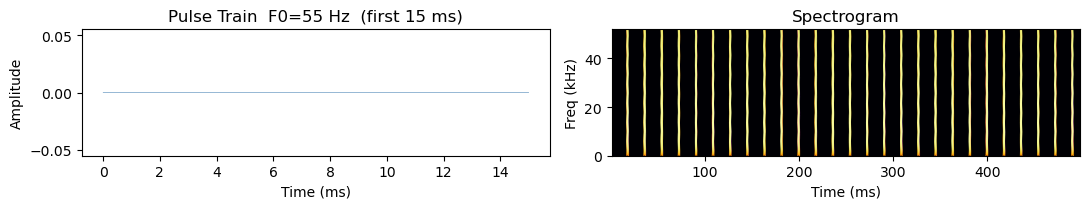

F0 = 55 Hz


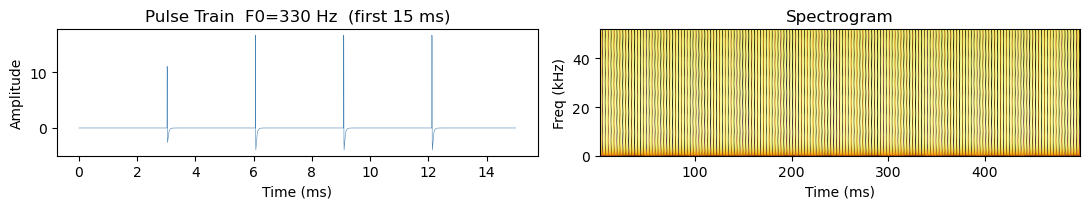

F0 = 330 Hz


In [5]:
# Pulse Train
for f0 in F0S:
    x = generate_stimulus(1, f0)
    t = np.arange(len(x)) / FS * 1e3
    fig, axes = plt.subplots(1, 2, figsize=(11, 2.2))
    axes[0].plot(t[:3000], x[:3000], lw=0.4, color='steelblue')
    axes[0].set(xlabel='Time (ms)', ylabel='Amplitude',
                title='Pulse Train  F0=' + str(f0) + ' Hz  (first 15 ms)')
    f, ts, Sxx = scipy.signal.spectrogram(x, fs=FS, nperseg=512, noverlap=448)
    mask = f <= 52_000
    axes[1].pcolormesh(ts * 1e3, f[mask] / 1e3,
                       10 * np.log10(Sxx[mask] + 1e-12),
                       shading='gouraud', cmap='inferno')
    axes[1].set(xlabel='Time (ms)', ylabel='Freq (kHz)',
                title='Spectrogram')
    plt.tight_layout(); plt.show()
    print('F0 =', f0, 'Hz')
    display(Audio(x, rate=FS))

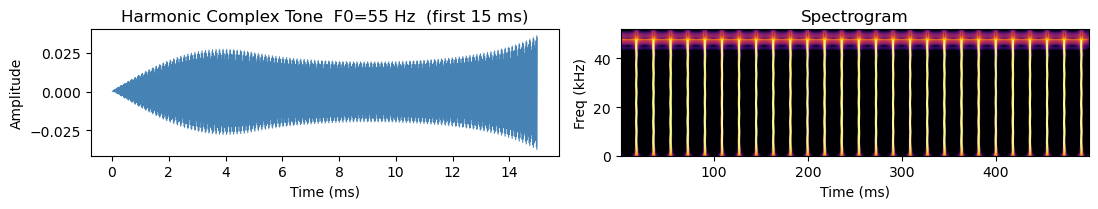

F0 = 55 Hz


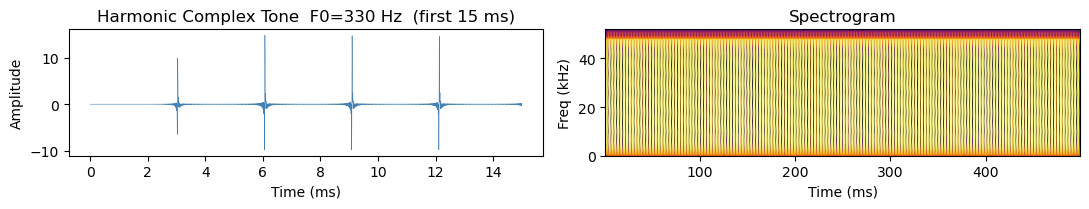

F0 = 330 Hz


In [6]:
# Harmonic Complex Tone
for f0 in F0S:
    x = generate_stimulus(2, f0)
    t = np.arange(len(x)) / FS * 1e3
    fig, axes = plt.subplots(1, 2, figsize=(11, 2.2))
    axes[0].plot(t[:3000], x[:3000], lw=0.4, color='steelblue')
    axes[0].set(xlabel='Time (ms)', ylabel='Amplitude',
                title='Harmonic Complex Tone  F0=' + str(f0) + ' Hz  (first 15 ms)')
    f, ts, Sxx = scipy.signal.spectrogram(x, fs=FS, nperseg=512, noverlap=448)
    mask = f <= 52_000
    axes[1].pcolormesh(ts * 1e3, f[mask] / 1e3,
                       10 * np.log10(Sxx[mask] + 1e-12),
                       shading='gouraud', cmap='inferno')
    axes[1].set(xlabel='Time (ms)', ylabel='Freq (kHz)',
                title='Spectrogram')
    plt.tight_layout(); plt.show()
    print('F0 =', f0, 'Hz')
    display(Audio(x, rate=FS))

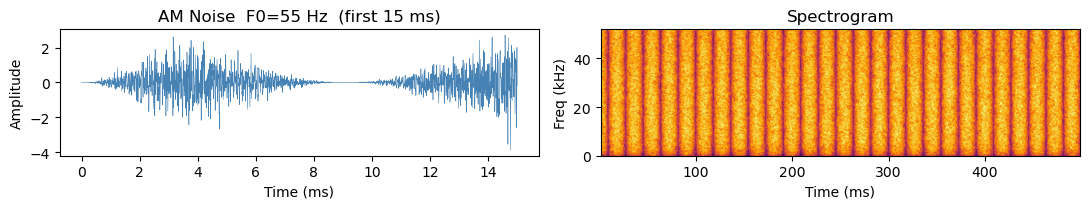

F0 = 55 Hz


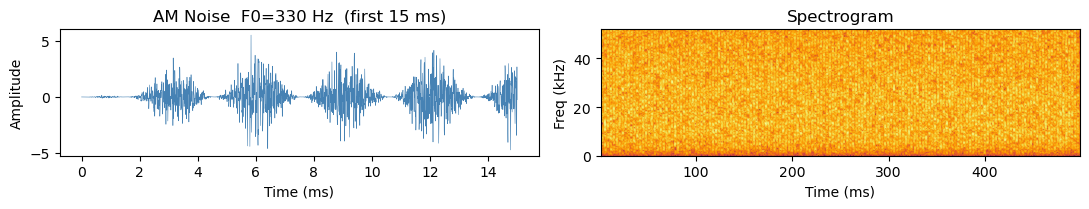

F0 = 330 Hz


In [7]:
# AM Noise
for f0 in F0S:
    x = generate_stimulus(3, f0)
    t = np.arange(len(x)) / FS * 1e3
    fig, axes = plt.subplots(1, 2, figsize=(11, 2.2))
    axes[0].plot(t[:3000], x[:3000], lw=0.4, color='steelblue')
    axes[0].set(xlabel='Time (ms)', ylabel='Amplitude',
                title='AM Noise  F0=' + str(f0) + ' Hz  (first 15 ms)')
    f, ts, Sxx = scipy.signal.spectrogram(x, fs=FS, nperseg=512, noverlap=448)
    mask = f <= 52_000
    axes[1].pcolormesh(ts * 1e3, f[mask] / 1e3,
                       10 * np.log10(Sxx[mask] + 1e-12),
                       shading='gouraud', cmap='inferno')
    axes[1].set(xlabel='Time (ms)', ylabel='Freq (kHz)',
                title='Spectrogram')
    plt.tight_layout(); plt.show()
    print('F0 =', f0, 'Hz')
    display(Audio(x, rate=FS))

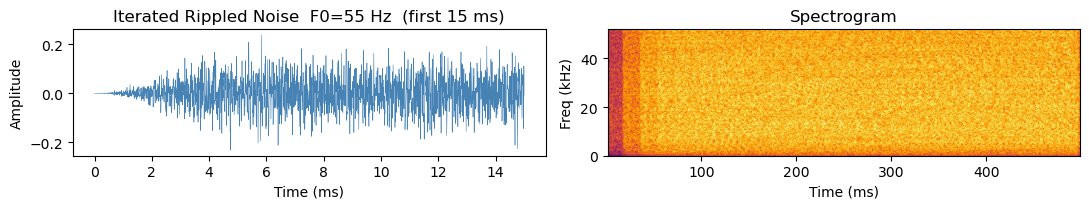

F0 = 55 Hz


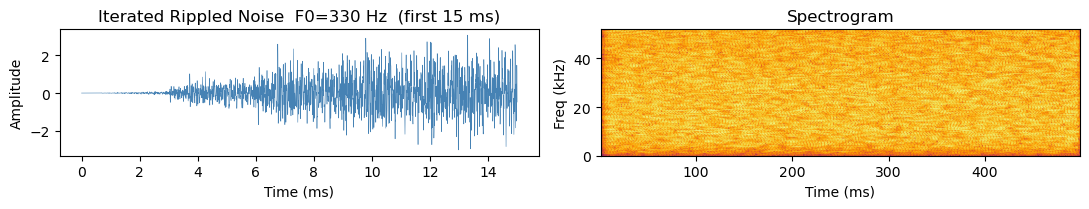

F0 = 330 Hz


In [8]:
# Iterated Rippled Noise
for f0 in F0S:
    x = generate_stimulus(4, f0)
    t = np.arange(len(x)) / FS * 1e3
    fig, axes = plt.subplots(1, 2, figsize=(11, 2.2))
    axes[0].plot(t[:3000], x[:3000], lw=0.4, color='steelblue')
    axes[0].set(xlabel='Time (ms)', ylabel='Amplitude',
                title='Iterated Rippled Noise  F0=' + str(f0) + ' Hz  (first 15 ms)')
    f, ts, Sxx = scipy.signal.spectrogram(x, fs=FS, nperseg=512, noverlap=448)
    mask = f <= 52_000
    axes[1].pcolormesh(ts * 1e3, f[mask] / 1e3,
                       10 * np.log10(Sxx[mask] + 1e-12),
                       shading='gouraud', cmap='inferno')
    axes[1].set(xlabel='Time (ms)', ylabel='Freq (kHz)',
                title='Spectrogram')
    plt.tight_layout(); plt.show()
    print('F0 =', f0, 'Hz')
    display(Audio(x, rate=FS))

## Auditory filterbank

Zero-phase 4th-order gammatone filters, CFs 4–48 kHz in 500 Hz steps.  
Bandwidths from Ehret (1976) mouse cochlear data (linear regression:  
`BW = 0.174 * CF + 422` Hz, derived from the original data).

In [9]:
def mouse_bw_ehret(fc):
    """Cochlear bandwidth from Ehret 1976 linear fit (fc in Hz -> BW in Hz)."""
    return 0.174 * fc + 422


def gammatone_kernel(fc, bw, fs=FS, order=GT_ORDER, kern_dur=GT_KERN_DUR):
    """4th-order gammatone impulse response."""
    n = int(kern_dur * fs)
    t = np.arange(n) / fs
    h = (t ** (order - 1)
         * np.exp(-2 * np.pi * bw * t)
         * np.cos(2 * np.pi * fc * t))
    h /= np.sqrt(np.sum(h ** 2))   # unit energy
    return h


def zerophase_gammatone(x, fc, bw=None, fs=FS):
    """Zero-phase gammatone filter: forward then time-reversed pass."""
    if bw is None:
        bw = mouse_bw_ehret(fc)
    h = gammatone_kernel(fc, bw, fs)
    # forward
    y = fftconvolve(x, h, mode='same')
    # backward (zero-phase trick: reverse, filter, reverse again)
    y = fftconvolve(y[::-1], h, mode='same')[::-1]
    return y

## Auditory model pipeline

For each filter channel:  
gammatone output → half-wave rectification → compression (^0.5) → LP@1kHz → ACF → pitch strength at lag 1/f0

In [10]:
def low_pass_1kHz(x, fs=FS):
    sos = butter(4, LP_CUTOFF, btype='low', fs=fs, output='sos')
    return sosfiltfilt(sos, x)


def acf_pitch_strength(y, f0, fs=FS):
    """
    Normalised autocorrelation peak at lag = 1/f0.
    Returns the ACF value at that lag (pitch strength for this channel).
    """
    lag = round(fs / f0)
    n   = len(y)
    # unnormalised ACF at target lag via dot product
    if lag >= n:
        return 0.0
    acf_0   = np.dot(y, y)           # lag 0 (power)
    acf_lag = np.dot(y[lag:], y[:-lag])
    return acf_lag / acf_0 if acf_0 > 0 else 0.0


def run_model(x, f0, cfs=None, fs=FS):
    """
    Run full auditory model on stimulus x.
    Returns (cfs, pitch_strengths) arrays.
    """
    if cfs is None:
        cfs = np.arange(CF_MIN, CF_MAX + 1, CF_STEP)
    strengths = np.zeros(len(cfs))
    for i, fc in enumerate(cfs):
        y = zerophase_gammatone(x, fc, fs=fs)   # filter
        y = np.maximum(y, 0)                     # half-wave rectify
        y = y ** 0.5                             # power-law compression
        y = low_pass_1kHz(y, fs)                 # phase-locking LP
        strengths[i] = acf_pitch_strength(y, f0, fs)
    return cfs, strengths

## Run model for all stimuli and F0s

Pitch strength (ACF peak at 1/f0) plotted across gammatone filter CFs.  
Higher = stronger pitch representation in that frequency channel.

Processing Pulse Train F0=55 Hz ...
Processing Harmonic Complex Tone F0=55 Hz ...
Processing AM Noise F0=55 Hz ...
Processing Iterated Rippled Noise F0=55 Hz ...


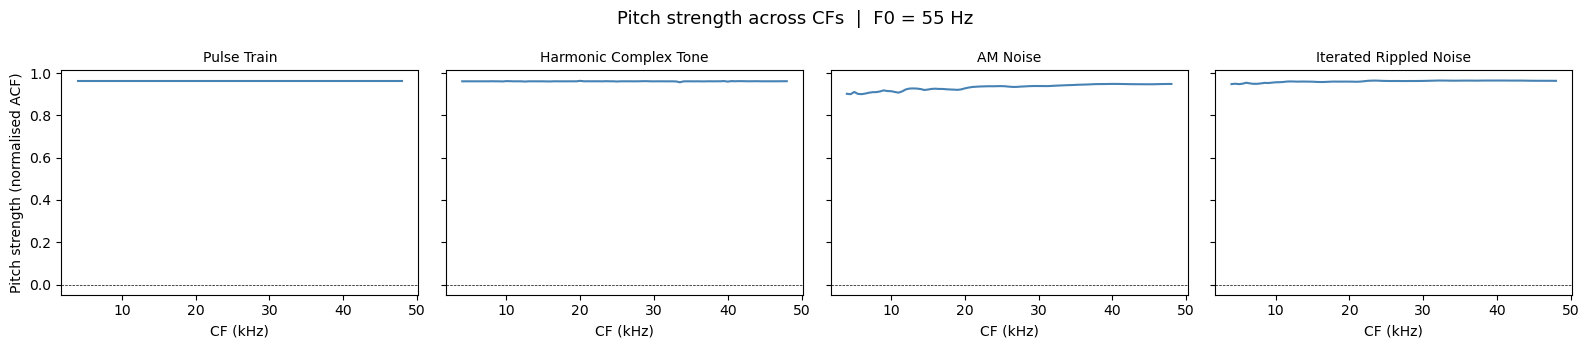


Processing Pulse Train F0=330 Hz ...
Processing Harmonic Complex Tone F0=330 Hz ...
Processing AM Noise F0=330 Hz ...
Processing Iterated Rippled Noise F0=330 Hz ...


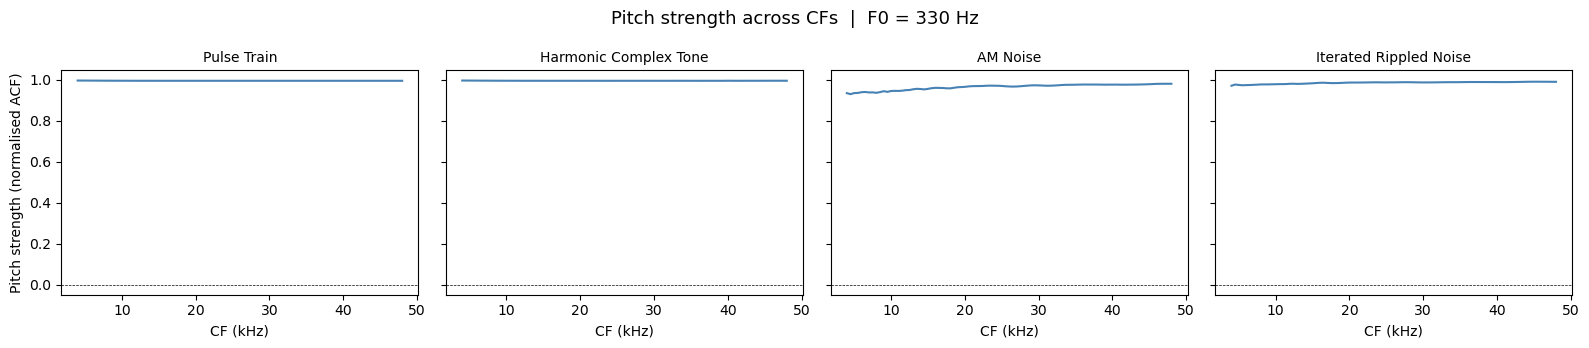

In [11]:
cfs = np.arange(CF_MIN, CF_MAX + 1, CF_STEP)

for f0 in F0S:
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
    fig.suptitle('Pitch strength across CFs  |  F0 = ' + str(f0) + ' Hz', fontsize=13)

    for ax, st in zip(axes, range(1, 5)):
        print('Processing', STIM_NAMES[st], 'F0=' + str(f0) + ' Hz ...', flush=True)
        x = generate_stimulus(st, f0)
        _, strengths = run_model(x, f0, cfs)

        ax.plot(cfs / 1000, strengths, color='steelblue', lw=1.5)
        ax.axhline(0, color='k', lw=0.5, ls='--')
        ax.set_xlabel('CF (kHz)')
        ax.set_title(STIM_NAMES[st], fontsize=10)
        if st == 1:
            ax.set_ylabel('Pitch strength (normalised ACF)')

    plt.tight_layout()
    plt.show()
    print()

## Summary: mean pitch strength per stimulus type

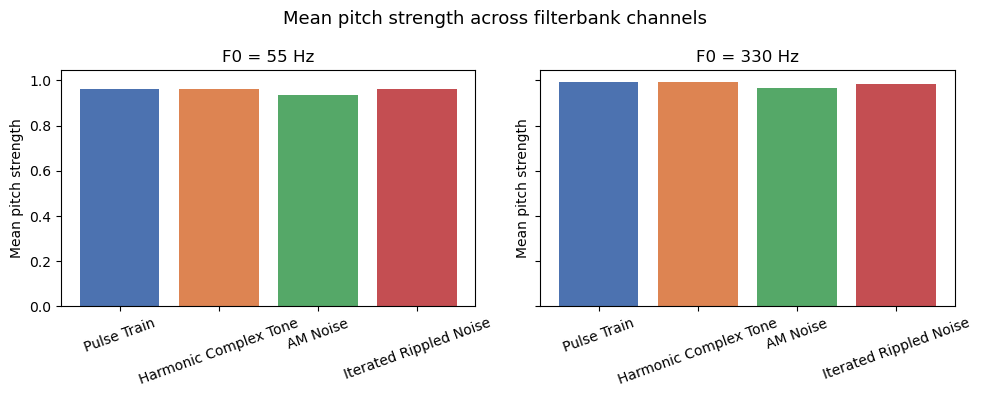

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

for ax, f0 in zip(axes, F0S):
    means = []
    for st in range(1, 5):
        x = generate_stimulus(st, f0)
        _, s = run_model(x, f0, cfs)
        means.append(np.mean(s))

    bars = ax.bar([STIM_NAMES[i+1] for i in range(4)], means,
                  color=['#4C72B0','#DD8452','#55A868','#C44E52'])
    ax.set_title('F0 = ' + str(f0) + ' Hz')
    ax.set_ylabel('Mean pitch strength')
    ax.tick_params(axis='x', rotation=20)

plt.suptitle('Mean pitch strength across filterbank channels', fontsize=13)
plt.tight_layout()
plt.show()